In [1]:
from typing import Optional

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
import seaborn as sns
import yaml
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

ox.settings.use_cache = True
ox.settings.log_console = False

with open("plotting_config.yaml") as fp:
    config = yaml.safe_load(fp)


def get_dominant_comm(df: pd.DataFrame) -> pd.DataFrame:
    return (
        df.sort_values("area_symmdiff")
        .drop_duplicates(subset=["run", "resolution", "barrier_id"], keep="first")
        .sort_values(["run", "resolution", "community_id", "barrier_id"])
    )

In [2]:
duna = gpd.read_file("../data/barriers/duna.geojson", engine="pyogrio")
duna.to_crs(23700, inplace=True)
districts = gpd.read_file(
    "../data/barriers/budapest_districts.geojson", engine="pyogrio"
)
districts.to_crs(23700, inplace=True)

districts["did"] = pd.to_numeric(districts["did"])
districts = districts[["did", "geometry"]].copy()
districts["area"] = round(districts["geometry"].area / 1e6, 3)

m3 = gpd.read_file("../data/barriers/m3.geojson", engine="pyogrio")
m3.to_crs(23700, inplace=True)

In [3]:
d15_eov = districts.query("did==15").reset_index().geometry
d15_gps = districts.query("did==15").reset_index().to_crs(4326).geometry

In [4]:
distr = pd.read_csv(
    "../data/symmetric_area_difference/communities_vs_districts_area_symmdiff.csv"
)

In [5]:
distr_ = get_dominant_comm(distr)
distr_["area_symmdiff"] = round(distr_["area_symmdiff"] / 1e6, 4)
distr_.columns = ["run", "resolution", "community_id", "did", "distr_area_symmdiff"]
distr_ = distr_.merge(districts, on="did")
distr_["das_ratio"] = distr_["distr_area_symmdiff"] / distr_["area"]

In [6]:
def get_streets_for_geom(geom: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    bbox = (
        geom.bounds["minx"][0] * 0.9995,
        geom.bounds["miny"][0] * 0.9995,
        geom.bounds["maxx"][0] * 1.0005,
        geom.bounds["maxy"][0] * 1.0005,
    )  # minX, minY, maxX, maxY
    g = ox.graph_from_bbox(bbox, simplify=False, retain_all=True)
    streets = ox.graph_to_gdfs(g, nodes=False)
    return streets

In [7]:
# c_land = "#eee8aa6f"
# c_street = "#d2b48c"
c_block = "#1e90ff"


def plot_district_area(
    streets: gpd.GeoDataFrame,
    district: gpd.GeoDataFrame,
    fillcolor: str = c_block + "5f",
    edgecolor: str = config["colors"]["darkblue"] + "8f",
    linewidth: float = 1,
) -> tuple[plt.Figure, plt.Axes]:
    area = streets.union_all().convex_hull
    land = gpd.GeoSeries(area.difference(duna.union_all()))

    fig, ax = plt.subplots(figsize=(3.3, 6), layout="constrained")

    land.plot(color=config["colors"]["land"], ax=ax, zorder=1)
    # gpd.clip(streets, area).plot(
    #     color=config["colors"]["street"], linewidth=0.25, ax=ax, zorder=2
    # )
    district.plot(ax=ax, ec=edgecolor, fc=fillcolor, zorder=5, lw=linewidth)

    ax.margins(0)
    ax.axis("off")
    return fig, ax

In [8]:
def foo(j: float, did: int, ax: plt.Axes):
    temp = distr_.query(f"did == {did}").copy()
    max_ = np.ceil(temp["distr_area_symmdiff"].max())
    d_area = districts.loc[districts["did"] == did, "area"].values[0]
    max_ = min(max_, d_area * 5)

    sns.lineplot(
        data=temp,
        x="resolution",
        y="distr_area_symmdiff",
        hue="run",
        palette="crest",
        # legend="full"
        legend=False,
        ax=ax,
    )
    # f = a.get_figure()
    # a.set_title(f"District {did}")
    ax.set_ylabel("SAD ($km^2$)", fontsize=12)
    ax.set_xlabel("felbontás", fontsize=12)
    ax.set_ylim([0, max_])
    ax.set_xlim([0.75, 10])
    ax.margins(0)

    ax.axhline(y=d_area, color="#2d2d2d", linestyle="dotted", linewidth=1)
    ax.axvline(x=j, color="#ff4500", linestyle="solid", linewidth=2)

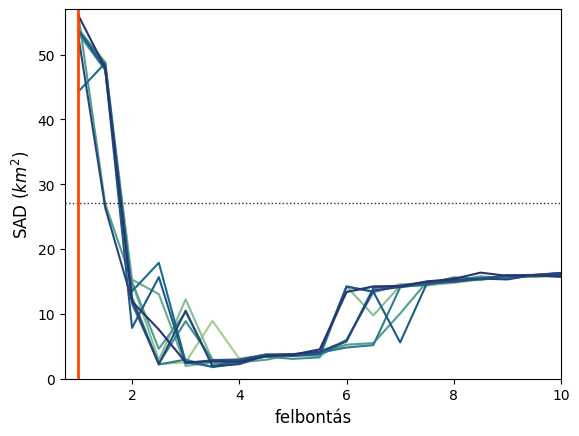

In [9]:
_, a = plt.subplots()
foo(1.0, 15, a)

In [10]:
streets_d15 = get_streets_for_geom(d15_gps)
streets_d15.to_crs(23700, inplace=True)

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

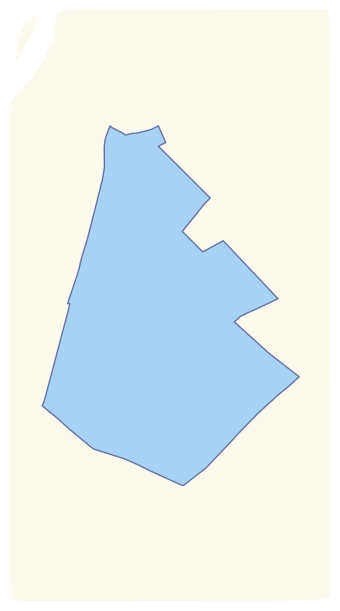

In [11]:
fig_d15, ax_d15 = plot_district_area(streets_d15, d15_eov)
iax = inset_axes(
    ax_d15,
    width=1.5,
    height=1.35,  # inch
    bbox_transform=ax_d15.transAxes,  # relative axes coordinates
    bbox_to_anchor=(1, 1),
)
iax.axis("off")

# for i in ["png"]:
#     fig_d15.savefig(
#         f"../paper/figures/d15.{i}",
#         dpi=300,
#         facecolor="white",
#         pad_inches=0,
#         metadata=config["metadata"] if i != "svg" else None)

In [16]:
fc = ["#009e737f", "#0072b27f"]
ec = ["#009e73", "#0072b2"]


def plot_communities_against_district(
    streets: gpd.GeoDataFrame,
    d_eov: gpd.GeoDataFrame,
    did: int,
    extra: list = [],
    extra_threshold: Optional[float] = None,
):
    area = streets.union_all().convex_hull
    # for i in np.arange(1, 10.5, 0.5):
    for i in [2.5, 4.0, 6.0, 6.5, 8.0]:
        f, a = plot_district_area(
            streets, d_eov, fillcolor="none", edgecolor="#d55e00", linewidth=2
        )
        c = gpd.read_file(
            f"../../papers/mobility-neighborhood-barriers/data/louvain_merged/0/louvain_r{i}_merged.geojson",
            engine="pyogrio",
        )
        c.to_crs(23700, inplace=True)
        c["intersection_area"] = c["geometry"].intersection(d_eov.geometry[0]).area
        c["ratio"] = (
            c["geometry"].intersection(d_eov.geometry[0]).area / d_eov.geometry[0].area
        )
        gpd.clip(c.query("ratio > 0.15"), area).plot(ax=a, ec=ec, fc=fc, zorder=10)

        if i >= extra_threshold:
            gpd.clip(extra, area).plot(color="black", ax=a, zorder=20)

        a.text(
            653750,
            252500,
            f"$\gamma = {i:0.1f}$",
            size=14,
            bbox=dict(boxstyle="Round", ec="#2d2d2d", fc="white"),
        )

        iax = inset_axes(
            a,
            width=1.35,
            height=1.2,  # inch
            bbox_transform=a.transAxes,  # relative axes coordinates
            bbox_to_anchor=(1, 1),
        )
        foo(i, did, ax=iax)
        # iax.axis("off")
        iax.set_xticks([])
        iax.set_yticks([])

        legend_elements = []
        labels = [
            "Legnagyobb közösség",
            "Második legnagyobb közösség",
            "15. kerület határa",
            "M3-as autópálya",
        ]
        lcolors = ["#009e737f", "#0072b27f", "#d55e00a0", "#2d2d2d"]
        types = ["Patch", "Patch", "Line2D", "Line2D"]
        n = len(c.query("ratio > 0.15"))
        for idx, (l, c, t) in enumerate(zip(labels, lcolors, types)):
            if n == 1 and idx == 1:
                continue
            if t == "Patch":
                elem = Patch(fc=c, label=l, alpha=1)
            if t == "Line2D":
                elem = Line2D([0], [0], c=c, label=l, alpha=1, lw=2)
            legend_elements.append(elem)

        legend = a.legend(
            handles=legend_elements,
            ncols=1,
            loc="lower center",
            framealpha=1,
            fontsize=11,
        )
        legend.set_zorder(100)

        for ext in ["png", "svg"]:
            f.savefig(
                f"../figures/d{did}_r{i}.{ext}",
                dpi=300,
                facecolor="white",
                pad_inches=0,
                metadata=config["metadata"] if ext != "svg" else None,
            )
        plt.close(f)

<>:36: SyntaxWarning: invalid escape sequence '\g'
<>:36: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_82029/3795906450.py:36: SyntaxWarning: invalid escape sequence '\g'
  f"$\gamma = {i:0.1f}$",


In [17]:
plot_communities_against_district(
    streets_d15, d15_eov, 15, extra=m3, extra_threshold=1.0
)
# runs 2m 7s

<Figure size 330x600 with 0 Axes>

<Figure size 330x600 with 0 Axes>

<Figure size 330x600 with 0 Axes>

<Figure size 330x600 with 0 Axes>

<Figure size 330x600 with 0 Axes>

<Figure size 330x600 with 0 Axes>

... (9 outputs left out)

<Figure size 330x600 with 0 Axes>

<Figure size 330x600 with 0 Axes>

<Figure size 330x600 with 0 Axes>

<Figure size 330x600 with 0 Axes>